In [4]:
from sklearn.datasets import make_classification
import numpy as np
import matplotlib.pyplot as plt

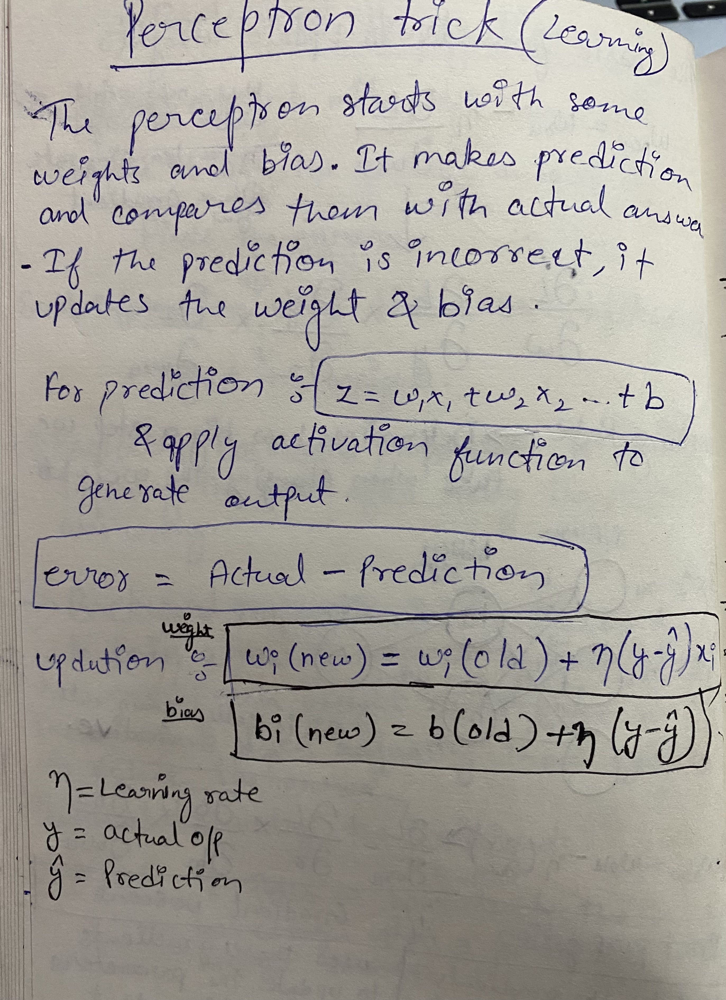
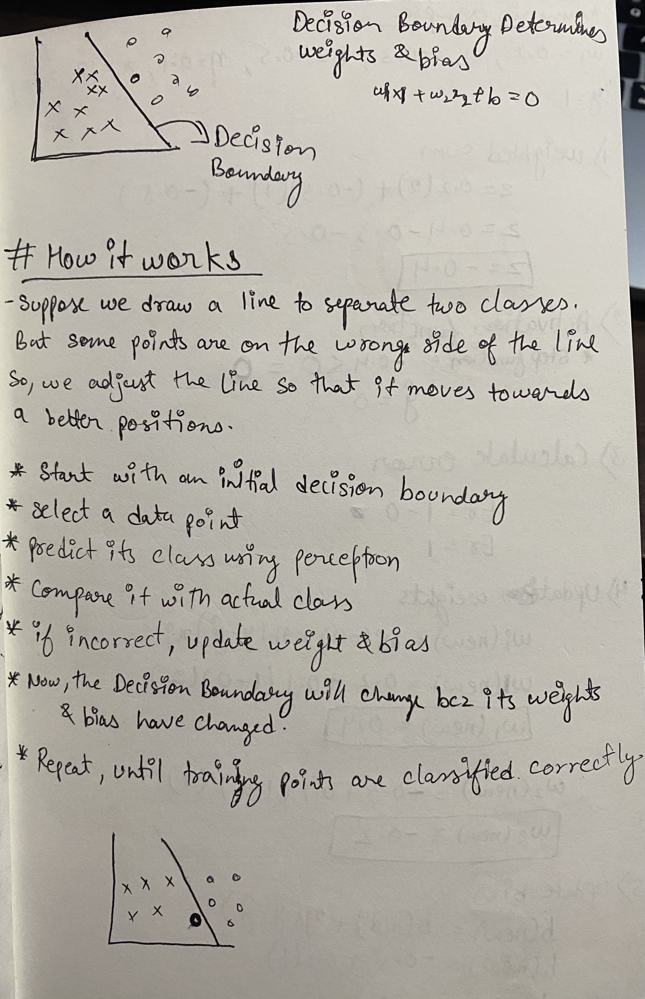
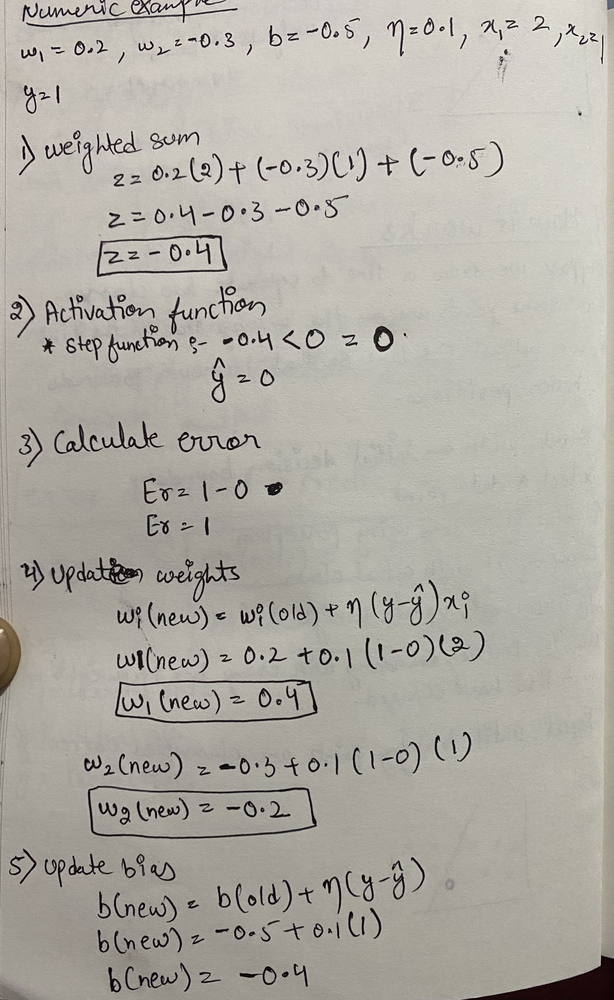
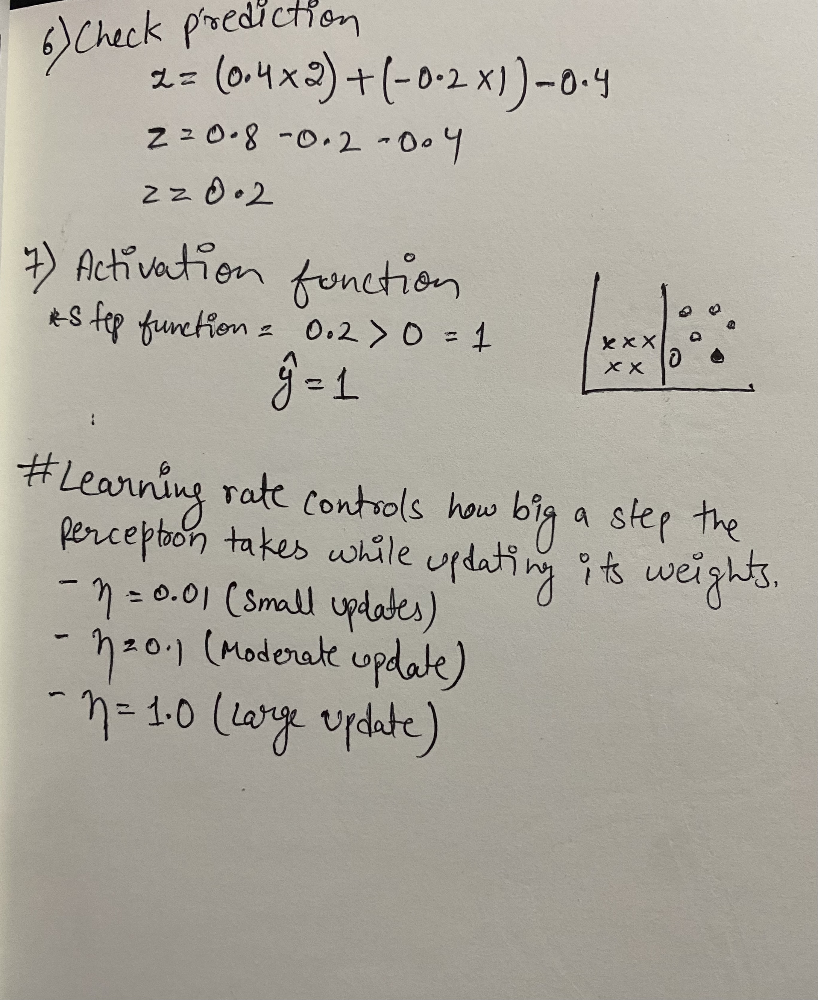

In [14]:
x, y = make_classification(n_samples=100, n_features=2, n_redundant=0, 
                           n_informative=1, n_classes=2, n_clusters_per_class=1,
                           random_state=41, hypercube=False, class_sep=10)

# n_redundant=0
# Redundant features are features that are generated as linear combinations of other informative 
# features.

# Suppose:
# - X₁ = Study hours
# - X₂ = 2 × X₁
# Here, X₂ doesn't provide genuinely new information because it can be calculated from X₁.

# By setting:
# n_redundant=0
# We tell the function not to generate any redundant features.



# n_informative=1
# Informative features are features that actually help the model predict the target variable.
# Suppose we have two features:
# - X₁ = Study hours
# - X₂ = Attendance
# But only X₁ contains useful information for predicting whether a student passes or fails.
# Then X₁ is informative, while X₂ doesn't provide additional predictive information.

# In our code:
# n_informative=1
# This means only one feature is informative.
# Important: The second feature is not necessarily redundant. It can contain random or otherwise uninformative variation.




# n_classes=2
# It specifies the number of output categories.
# Here we have two classes:
# - Class 0
# - Class 1




# hypercube=False
# This parameter controls how the cluster centers are generated.
# - hypercube=True: Cluster centers are initially placed at the vertices of a hypercube.
# - hypercube=False: Cluster centers are generated in a more general random arrangement.
# in simple language, it controls the initial positioning of the cluster centers.

In [40]:
import pandas as pd 
df = pd.DataFrame(x)
df.describe()

,0,1
count,100.000000,100.000000
mean,-0.530472,0.060770
std,1.158693,0.938258
min,-2.400676,-2.980924
25%,-1.496951,-0.544073
50%,-0.734673,0.172038
75%,0.564662,0.710422
max,2.144882,2.061587


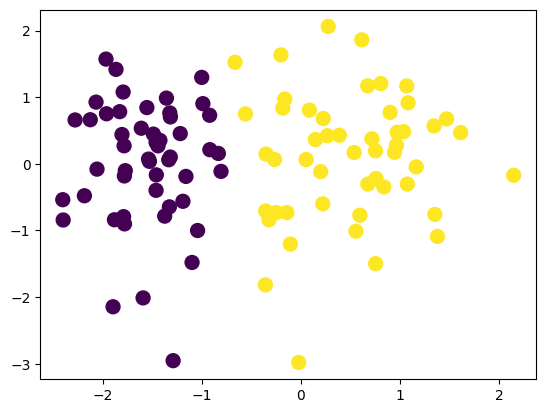

In [41]:
plt.scatter(x[:, 0], x[:, 1], c=y, s=100)

In [42]:
def step_fun(z): 
    return 1 if z >= 0 else 0


def perceptron(x ,y): 
    x = np.insert(x, 0, 1, axis=1) #this line creates a new column in x[0] in which all rows 
                            # consists value 1. basically for bias which we will use later (b(1)). 
    weights = np.ones(x.shape[1]) #x.shape[1] refers x's total columns and creating array of ones [1.,1.,1,]
    lr = 0.1 

    for i in range(1000): 
        j = np.random.randint(0,len(x))
        y_hat = step_fun(np.dot(x[j], weights)) #now we are predicting the output and the np.dot()
        # is used to calculate weighted sum (x0*w0)+(x1*w1)+(x2*w2) and here x0*w0 are the bias the x0 is constant(1) that is not affecting our bias value. 
        weights = weights + lr * (y[j] - y_hat) * x[j] # this will run every time but only changes the weights when the prdiction is wrong.

    return weights[0], weights[1:] #weights[0] is bias  and weights[1:] are the weights
    
        

In [43]:
intercept_, coef_ = perceptron(x,y)

In [44]:
print(f"Bias = {intercept_}")
print(f"weights = {coef_}")

Bias = 0.9
weights = [1.31120522 0.18753927]


(-3.0, 2.0)

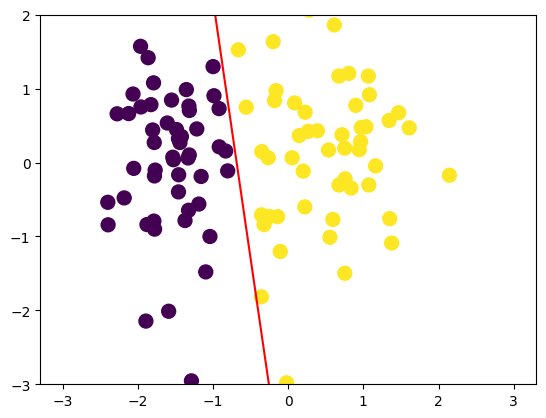

In [45]:
m = -(coef_[0]/coef_[1])
b = -(intercept_ / coef_[1])

# for generating coordinates for graph 
x_inp = np.linspace(-3,3,100) #we are creating coordinate from -3 to 3 because our dataset stores min_value = -2.980924
                              # max_value = 2.144882
y_inp = m * x_inp + b

plt.plot(x_inp, y_inp, color="red") 
plt.scatter(x[:, 0], x[:, 1], c=y, s=100)
plt.ylim(-3,2) #This controls the visible range of the y-axis. Minimum y-value = -3 and Maximum y-value = 2.


# This code is used to draw the decision boundary of your Perceptron model and visualize how it 
# separates two classes of data points.
# Perceptron model has learned two coefficients (weights) and one intercept (bias).
# Its decision boundary is:
# w1x1 + w2x2 + bias = 0

# To draw this line, we rearrange the equation:
# w2x2 = -w1x1 - bias

# x2 = -(w1/w2)x1 - (bias/w2)

# Compare this with (y=mx+b):
# - m = -(coef_[0] / coef_[1])
# - b = -(intercept_ / coef_[1])